# 07 — Results: headline table / 結果：headline table

**EN** Regenerates the holdout report from the cached holdout artifacts into `artifacts/rerun/holdout/` (no run-log row, the sealed data is not read) and compares its headline table with the committed `reports/holdout.md`.

*Needs `data/` and `artifacts/` from the shared Drive folder (see README).*

**中文** 從已快取的 holdout 產物重新產生報告到 `artifacts/rerun/holdout/`（不寫 run log、不讀封存資料），並與已 commit 的 `reports/holdout.md` 比對 headline table。

*需要先從 README 的 Drive 連結下載 `data/` 與 `artifacts/`。*

In [1]:
# Locate the repository root and load the library (works from the root or notebooks/)
# 找到 repo 根目錄並載入函式庫（從根目錄或 notebooks/ 執行皆可）
import os, sys, json, subprocess
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "setup.yaml").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import yaml
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 4)


def show(fig, width=820):
    """Show a committed figure / 顯示已產出的圖"""
    display(Image(filename=str(ROOT / "reports" / "figures" / fig), width=width))


def sh(cmd):
    """Run a repository command from the root and print its output / 在根目錄執行指令並印出結果"""
    r = subprocess.run(cmd, shell=True, cwd=ROOT, capture_output=True, text=True, encoding="utf-8")
    print(r.stdout[-4000:], r.stderr[-2000:])
    return r.returncode

In [2]:
# Regenerate the holdout report (about 1-2 minutes) / 重新產生 holdout 報告（約 1–2 分鐘）
rerun = ROOT / "artifacts" / "rerun" / "holdout"
rc = sh(f'python scripts/run_holdout.py report --rerun-dir "{rerun}"')
assert rc == 0

# Holdout evaluation (W6)

- **Frozen spec**: `config/holdout.yaml` (setup v1). Final models were fit once on dev rows with labels realized by 2025-10-25 and frozen for 2025-10-25..2026-10-24.
- **Trials for deflation**: 454.

## Confirmatory test (registered: ridge holdout IC, NW 95% CI lower bound > 0)

**PASS**: mean daily IC +0.1398, 95% CI [+0.1069, +0.1727], NW t +8.33, 358 days.
The result was written to `reports/holdout_confirmatory.json` at 2026-10-27T04:50:12+00:00 (git `0ba5579`), before the rest of this report was computed.

## Headline table (ridge, the deployed model; Table 20.2 layout)

| stage | metric | validation | holdout | benchmark |
|---|---|---|---|---|
| Signal | daily IC [HAC 95% CI] | +0.131 [+0.102, +0.160] | +0.140 [+0.107, +0.173] | — |
| Signal | ICIR (daily); share of positive months | 0.600; 0.91 of 32 | 0.916; 1.00 of 13 | — |
| Portfolio | gross Sharpe [95% CI]; max DD; turnover/yr | -0.06 [-1.26, +1.14]; 49%; 44 | -0.59 [-2.55, +1.37]; 55%; 33 | EW -0

In [3]:
# Compare the headline tables cell by cell / 逐格比對 headline table
from crowding.holdout import markdown_table
def headline(path):
    return markdown_table(Path(path).read_text(encoding="utf-8"), "## Headline table")

old, new = headline("reports/holdout.md"), headline(rerun / "holdout.md")
assert old.shape == new.shape == (6, 5), (old.shape, new.shape)
display(new)
same = (old == new)
print("identical cells / 相同格數:", int(same.values.sum()), "of / 共", same.size)
if not same.values.all():
    display(pd.concat({"committed": old[~same.all(axis=1)], "rerun": new[~same.all(axis=1)]}, axis=1))

,stage,metric,validation,holdout,benchmark
0,Signal,daily IC [HAC 95% CI],"+0.131 [+0.102, +0.160]","+0.140 [+0.107, +0.173]",—
1,Signal,ICIR (daily); share of positive months,0.600; 0.91 of 32,0.916; 1.00 of 13,—
2,Portfolio,gross Sharpe [95% CI]; max DD; turnover/yr,"-0.06 [-1.26, +1.14]; 49%; 44","-0.59 [-2.55, +1.37]; 55%; 33",EW -0.34 (DD 47%); BTC -0.58 (DD 50%)
3,Costs,net Sharpe [95% CI]; break-even bp/leg,"-0.19 [-1.39, +1.02]; -4.3","-0.68 [-2.64, +1.28]; -70.4",—
4,Risk overlay,net Sharpe; max DD with vol target 20%,-0.18; 34%,-0.69; 36%,—
5,Inference,Deflated Sharpe (trials = 454); min track reco...,0.000; ∞,0.000; ∞,—


identical cells / 相同格數: 30 of / 共 30


**EN** Differences, if any, are explained in the README (data download date, vendor revisions, Colab GPU nondeterminism for the deep model).

**中文** 若有差異，原因寫在 README（資料下載日期、vendor 修正、深度模型在 Colab GPU 上的非決定性）。

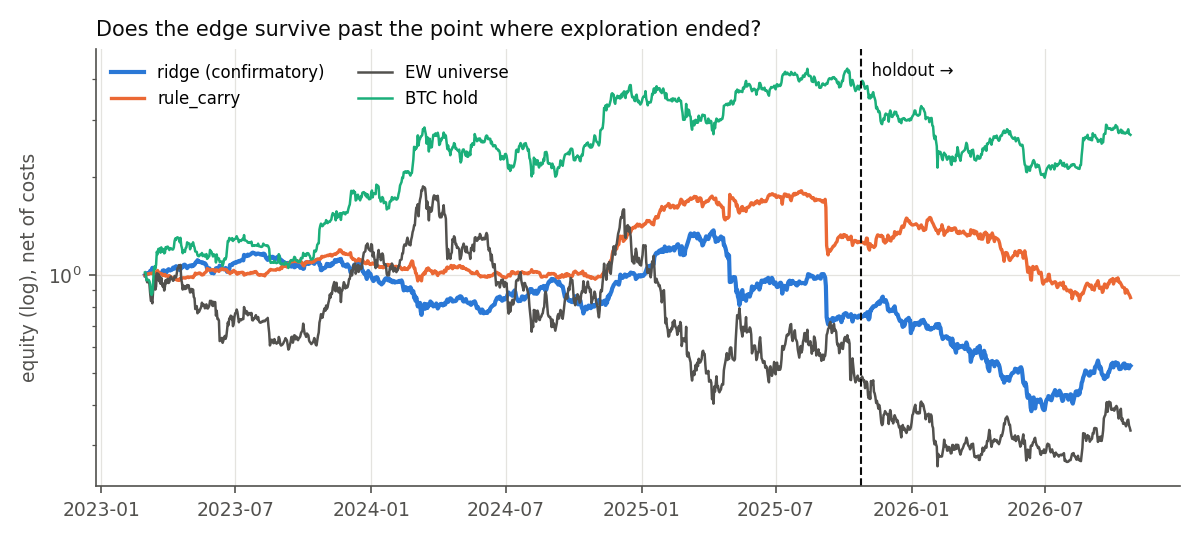

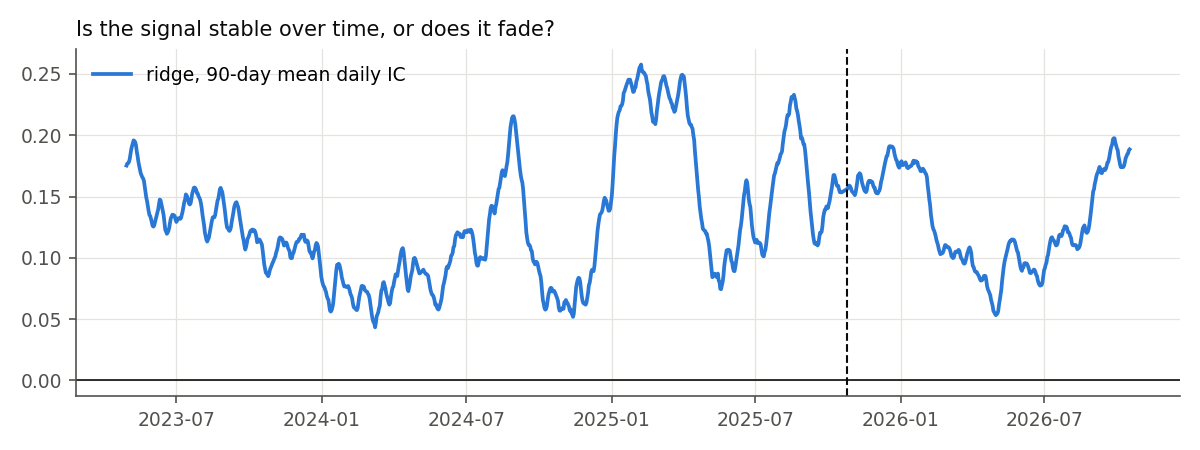

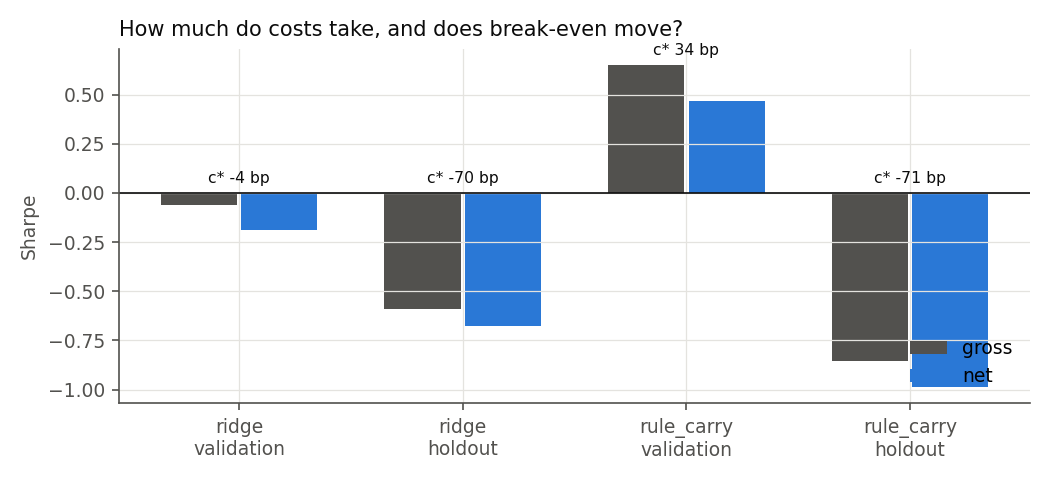

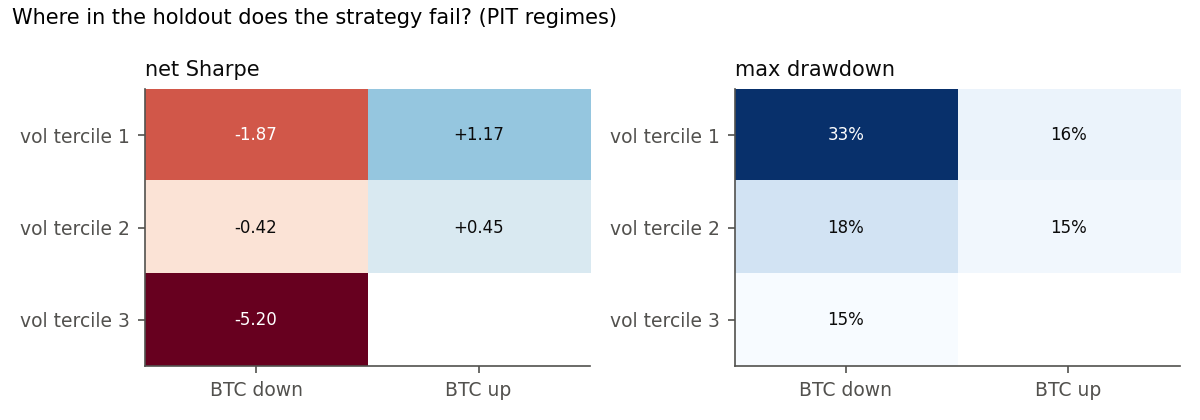

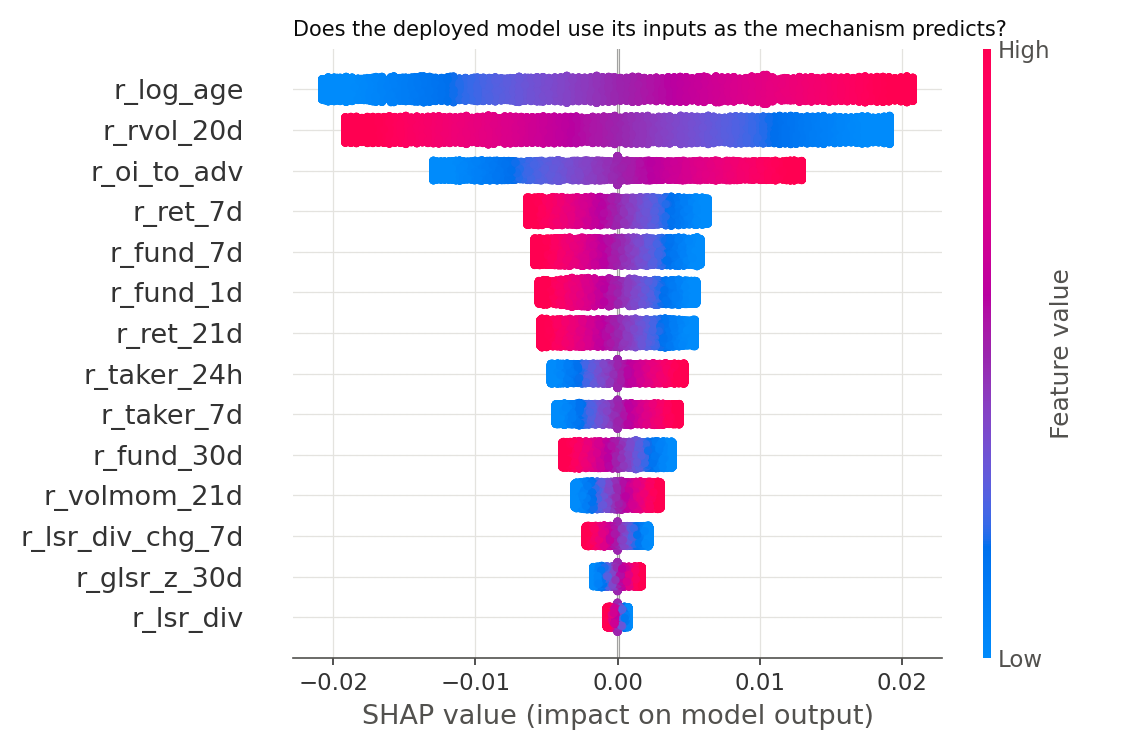

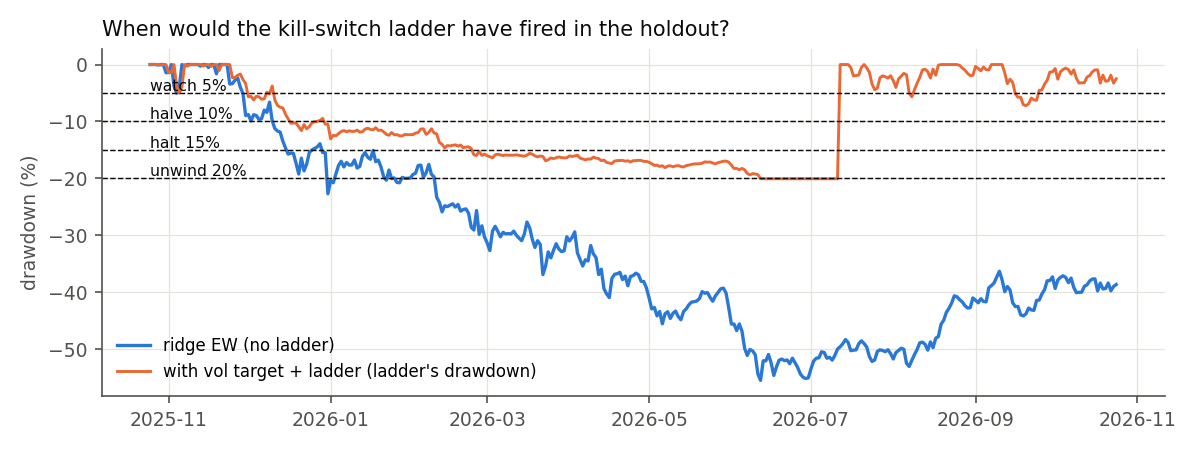

In [4]:
# Six required figures / 六張必附圖
for f in ("holdout_1_equity.png", "holdout_2_rolling_ic.png", "holdout_3_gross_net.png",
          "holdout_4_regime.png", "holdout_5_shap.png", "holdout_6_drawdown.png"):
    display(Image(filename=str(rerun / "figures" / f), width=820))

In [5]:
# Outcome pattern and diagnosis from the committed report / 結果型態與診斷
import re
text = Path("reports/holdout.md").read_text(encoding="utf-8")
display(Markdown(re.search(r"\*\*Outcome.*?(?=\n\n)", text, re.S).group(0)))

**Outcome (Chapter 20 patterns, registered rules)**: the signal **strengthens**; the net PnL is **never resolved**. The validation and holdout IC intervals overlap ([+0.102, +0.160] vs [+0.107, +0.173]), so the difference between them is within sampling error: read the IC as having held, not as a measured improvement.